# Transparent Survival Analysis Using Tree-Based Ensembles

## Project overview

Survival analysis examines the time until an event occurs while accounting for observations in which the event has not been observed by the end of follow-up. In healthcare, survival models can support the study of patient outcomes and the identification of factors associated with differences in risk.

Predictive performance is only one consideration when evaluating these models. Feature-importance explanations are also relevant, but their rankings may change when a model is trained on a different sample of patients.

This project investigates the relationship between training sample size, predictive performance, and feature-importance stability using the German Breast Cancer Study Group 2 (GBSG2) dataset. Three survival models are compared: Cox Proportional Hazards, Random Survival Forest, and Gradient-Boosted Survival.

## Research questions

1. How does training sample size affect the predictive performance of survival models?
2. How does training sample size affect the stability of feature-importance rankings across models trained on different patient samples?
3. How does overlap between training samples affect the apparent agreement between feature-importance rankings?

## Analysis approach

The analysis combines model development and evaluation with a repeated sample-size experiment. Predictive performance is assessed on a held-out test set. Feature-importance stability is examined by comparing rankings from models trained on disjoint and overlapping patient samples, alongside reference estimates of permutation-related noise.

The notebook is organized into data exploration, preprocessing, model development, predictive evaluation, risk stratification, feature-importance analysis, sample-size experiments, and interpretation of results.



# 0. Environment setup

The notebook was developed in Google Colab. The following cells install and load the packages required for survival modelling, data preparation, statistical analysis, and visualization.

Run the installation cell before executing the analysis. If the environment requests a runtime restart after installation, restart once and then run the notebook from the beginning. A CPU runtime is sufficient for the analysis.


In [1]:
%pip install -q scikit-survival==0.28.0 lifelines==0.30.3

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


# 1. Setup

In [2]:
import os, sys, time, pickle, warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import spearmanr, weightedtau

import sklearn
import sksurv
import lifelines

warnings.filterwarnings("ignore", category=FutureWarning)

print("Python:", sys.version.split()[0])
for lib in [np, pd, scipy, sklearn, sksurv, lifelines]:
    print(f"{lib.__name__}: {lib.__version__}")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

GLOBAL_SEED = 42
rng_global = np.random.default_rng(GLOBAL_SEED)

def derived_seed(*keys):
    # Reproducible integer seed derived from GLOBAL_SEED and the given keys
    return int(np.random.SeedSequence([GLOBAL_SEED, *keys]).generate_state(1)[0])

Python: 3.13.18
numpy: 2.1.3
pandas: 2.2.3
scipy: 1.16.3
sklearn: 1.9.1
sksurv: 0.28.0
lifelines: 0.30.3


The analysis uses the package versions recorded in the environment setup. The principal survival-analysis dependencies are `scikit-survival==0.28.0` and `lifelines==0.30.3`.


In [3]:
# Experiment size. Reduce N_PAIRS for a quick test run.
N_PAIRS = 25            # disjoint (and overlapping) model pairs per sample size
IMPORTANCE_REPEATS = 10 # permutation shuffles per feature group per fitted model
NOISE_REPLICATES = 30   # replicates for the noise-floor analysis
N_BOOT = 500            # bootstrap resamples for test-set confidence intervals
N_JOBS = -1             # use all available CPU cores

# Long-running results are saved here and reloaded if the settings match.
# On Colab, to keep results across sessions, mount Google Drive first:
#   from google.colab import drive; drive.mount("/content/drive")
#   RESULTS_DIR = "/content/drive/MyDrive/gbsg2_results"
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

def cached(name, settings, compute):
    # Load a saved result if it was produced with the same settings; otherwise compute and save it.
    path = os.path.join(RESULTS_DIR, f"{name}.pkl")
    if os.path.exists(path):
        with open(path, "rb") as f:
            saved = pickle.load(f)
        if saved["settings"] == settings:
            print(f"Loaded saved results: {path}")
            return saved["result"]
    result = compute()
    with open(path, "wb") as f:
        pickle.dump({"settings": settings, "result": result}, f)
    print(f"Saved results: {path}")
    return result

# 2. Data

In [4]:
from sksurv.datasets import load_gbsg2

X, y = load_gbsg2()

print("Patients:", X.shape[0], "| Predictors:", X.shape[1])
print("Events:", int(y["cens"].sum()), f"({100 * y['cens'].mean():.1f}%)")
print("Censored:", int((~y["cens"]).sum()))
print("Missing values:", int(X.isna().sum().sum()))
print("\nNote: in scikit-survival's GBSG2, the field 'cens' is the EVENT indicator (True = recurrence or death).")
display(X.head())

Patients: 686 | Predictors: 8
Events: 299 (43.6%)
Censored: 387
Missing values: 0

Note: in scikit-survival's GBSG2, the field 'cens' is the EVENT indicator (True = recurrence or death).


,age,estrec,horTh,menostat,pnodes,progrec,tgrade,tsize
0,70.0,66.0,no,Post,3.0,48.0,II,21.0
1,56.0,77.0,yes,Post,7.0,61.0,II,12.0
2,58.0,271.0,yes,Post,9.0,52.0,II,35.0
3,59.0,29.0,yes,Post,4.0,60.0,II,17.0
4,73.0,65.0,no,Post,1.0,26.0,II,35.0


,count,mean,std,min,25%,50%,75%,max
age,686.0,53.05,10.12,21.0,46.0,53.0,61.00,80.0
estrec,686.0,96.25,153.08,0.0,8.0,36.0,114.00,1144.0
pnodes,686.0,5.01,5.48,1.0,1.0,3.0,7.00,51.0
progrec,686.0,110.00,202.33,0.0,7.0,32.5,131.75,2380.0
tsize,686.0,29.33,14.30,3.0,20.0,25.0,35.00,120.0


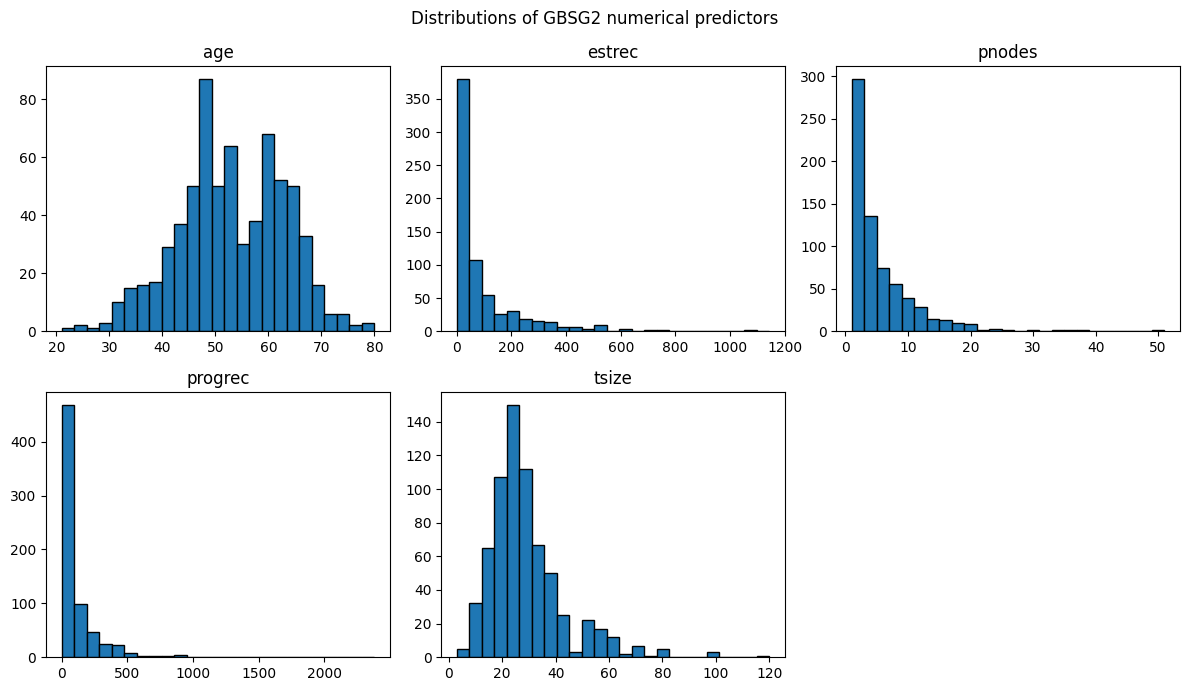

Skewness:


,skewness
age,-0.15
estrec,3.09
pnodes,2.88
progrec,4.79
tsize,1.78


In [5]:
display(X.describe().T.round(2))

numeric_cols = X.select_dtypes(include="number").columns
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.ravel(), numeric_cols):
    ax.hist(X[col], bins=25, edgecolor="black")
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.suptitle("Distributions of GBSG2 numerical predictors")
plt.tight_layout()
plt.show()

print("Skewness:")
display(X[numeric_cols].skew().round(2).to_frame("skewness"))

The distributions indicate that `pnodes`, `progrec`, and `estrec` are strongly right-skewed. This is relevant to the Cox model because its linear predictor assumes a linear relationship between each predictor and log hazard. Tree-based models can capture nonlinear splits without requiring the same transformation.

For the Cox model, the raw predictor specification is therefore compared with a specification using `log(1 + x)` for these three variables. The choice is made using cross-validation on the training data; the held-out test set is not used for this model-selection decision.


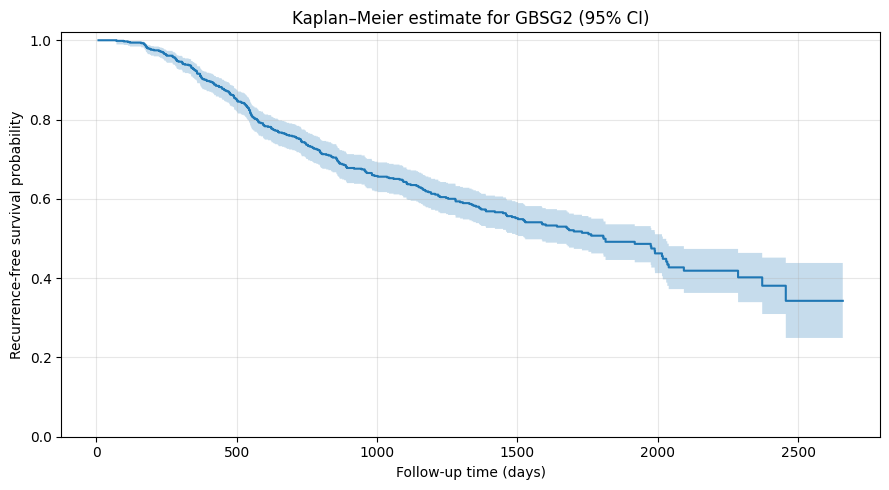

In [6]:
from sksurv.nonparametric import kaplan_meier_estimator

t_km, s_km, ci = kaplan_meier_estimator(y["cens"], y["time"], conf_type="log-log")

plt.figure(figsize=(9, 5))
plt.step(t_km, s_km, where="post")
plt.fill_between(t_km, ci[0], ci[1], step="post", alpha=0.25)
plt.xlabel("Follow-up time (days)")
plt.ylabel("Recurrence-free survival probability")
plt.title("Kaplan–Meier estimate for GBSG2 (95% CI)")
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Train/test split and preprocessing

The 686 observations are divided into a stratified 75% training set and a 25% held-out test set. Stratification keeps the event proportion approximately consistent across the two sets.

The training set is used for model selection, hyperparameter tuning, and the sample-size experiments. The test set is reserved for final predictive evaluation and test-set feature-importance calculations.

Categorical predictors are one-hot encoded. The encoder is fitted on the training predictors only and then applied to the test predictors. This prevents information from the test set from influencing preprocessing.


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

indices = np.arange(len(X))
train_idx, test_idx = train_test_split(
    indices, test_size=0.25, random_state=GLOBAL_SEED, stratify=y["cens"]
)

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y[train_idx], y[test_idx]

print("Training:", len(X_train), "patients,", int(y_train["cens"].sum()), "events")
print("Test:", len(X_test), "patients,", int(y_test["cens"].sum()), "events")

categorical_cols = ["horTh", "menostat", "tgrade"]
skewed_cols = ["pnodes", "progrec", "estrec"]

# The encoder is fitted on training data only
encoder = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
encoder.fit(X_train[categorical_cols])

def prepare(data, log_skewed=False):
    encoded = pd.DataFrame(
        encoder.transform(data[categorical_cols]),
        columns=encoder.get_feature_names_out(categorical_cols),
        index=data.index,
    )
    numeric = data.drop(columns=categorical_cols).copy()
    if log_skewed:
        for col in skewed_cols:
            numeric[col] = np.log1p(numeric[col])
    return pd.concat([numeric, encoded], axis=1)

X_train_raw, X_test_raw = prepare(X_train), prepare(X_test)
X_train_log, X_test_log = prepare(X_train, True), prepare(X_test, True)

# Map each encoded column back to its original clinical variable
feature_groups = {}
for col in X_train_raw.columns:
    original = next((c for c in categorical_cols if col.startswith(c + "_")), col)
    feature_groups.setdefault(original, []).append(col)

print("\nFeature groups used for grouped permutation importance:")
for k, v in feature_groups.items():
    print(f"  {k}: {v}")

Training: 514 patients, 224 events
Test: 172 patients, 75 events

Feature groups used for grouped permutation importance:
  age: ['age']
  estrec: ['estrec']
  pnodes: ['pnodes']
  progrec: ['progrec']
  tsize: ['tsize']
  horTh: ['horTh_yes']
  menostat: ['menostat_Pre']
  tgrade: ['tgrade_II', 'tgrade_III']


# 4. Cox model: functional form and proportional-hazards assessment

Two Cox model specifications are compared using five-fold cross-validated C-index on the training data:

- the original predictor values; and
- `log(1 + x)` transformations for the three strongly right-skewed predictors: `pnodes`, `progrec`, and `estrec`.

The specification with the stronger cross-validation performance is selected for the remaining analysis. The held-out test set does not influence this decision.

Schoenfeld-residual tests are then used to assess the proportional-hazards assumption for the selected Cox model.


In [8]:
from sklearn.model_selection import StratifiedKFold
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.metrics import concordance_index_censored

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=GLOBAL_SEED)
cv_splits = list(cv.split(X_train_raw, y_train["cens"]))

def cv_cindex(make_model, X_tr):
    scores = []
    for tr, va in cv_splits:
        m = make_model().fit(X_tr.iloc[tr], y_train[tr])
        risk = m.predict(X_tr.iloc[va])
        scores.append(concordance_index_censored(
            y_train[va]["cens"], y_train[va]["time"], risk)[0])
    return np.mean(scores), np.std(scores, ddof=1)

cox_cv = pd.DataFrame([
    {"specification": "Raw predictors", **dict(zip(["cv_c_index", "cv_sd"],
        cv_cindex(CoxPHSurvivalAnalysis, X_train_raw)))},
    {"specification": "log(1 + x) for pnodes, progrec, estrec", **dict(zip(["cv_c_index", "cv_sd"],
        cv_cindex(CoxPHSurvivalAnalysis, X_train_log)))},
])
display(cox_cv.round(4))

USE_LOG = cox_cv.loc[1, "cv_c_index"] > cox_cv.loc[0, "cv_c_index"]
print("Selected specification:", "log-transformed" if USE_LOG else "raw")

# One design matrix for all models. Trees are invariant to monotone transforms,
# so this choice only affects the Cox model.
X_tr = X_train_log if USE_LOG else X_train_raw
X_te = X_test_log if USE_LOG else X_test_raw

,specification,cv_c_index,cv_sd
0,Raw predictors,0.6716,0.0520
1,"log(1 + x) for pnodes, progrec, estrec",0.6872,0.0392


Selected specification: log-transformed


In [9]:
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test

lifelines_df = X_tr.copy()
lifelines_df["time"] = y_train["time"]
lifelines_df["event"] = y_train["cens"].astype(int)

cph = CoxPHFitter()
cph.fit(lifelines_df, duration_col="time", event_col="event")

ph_test = proportional_hazard_test(cph, lifelines_df, time_transform="rank")
ph_table = ph_test.summary[["test_statistic", "p"]].rename(columns={"p": "p_value"})
display(ph_table.round(4))

print("Hazard ratios (selected specification, training set):")
display(cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3))

,test_statistic,p_value
age,0.5987,0.4391
estrec,2.3830,0.1227
horTh_yes,0.4777,0.4895
menostat_Pre,0.4140,0.5199
pnodes,3.6768,0.0552
progrec,0.3572,0.5500
tgrade_II,0.4764,0.4901
tgrade_III,2.8199,0.0931
tsize,1.7654,0.1839


Hazard ratios (selected specification, training set):


,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
age,0.986,0.966,1.007,0.204
estrec,1.052,0.958,1.156,0.289
pnodes,1.873,1.548,2.266,0.000
progrec,0.822,0.751,0.900,0.000
tsize,1.001,0.992,1.010,0.895
horTh_yes,0.668,0.498,0.895,0.007
menostat_Pre,0.796,0.520,1.219,0.294
tgrade_II,1.788,1.001,3.193,0.049
tgrade_III,1.838,0.969,3.487,0.062


Schoenfeld-residual p-values provide diagnostic evidence about whether a predictor's hazard ratio changes over follow-up time. A small p-value may indicate a departure from the proportional-hazards assumption. Because several terms are tested, the overall pattern is more informative than treating one borderline result as conclusive.

A test that does not identify a clear violation does not prove that the assumption is perfectly satisfied. If the assumption is imperfect, the Cox model may still provide useful risk rankings, but its hazard-ratio estimates should not automatically be interpreted as constant over time. The tree-based survival models do not rely on the same proportional-hazards assumption.


# 5. Hyperparameter tuning

Random Survival Forest and Gradient-Boosted Survival are tuned using grid search with five-fold cross-validation on the training set. The same cross-validation folds are used for the Cox-model comparison to support a more direct comparison of model-selection results.

The boosting search includes a wider range of configurations than the earlier version. The selected settings from this tuning step are used in the subsequent test-set and sample-size experiments.


In [10]:
from sklearn.model_selection import GridSearchCV
from sksurv.ensemble import RandomSurvivalForest, GradientBoostingSurvivalAnalysis

t0 = time.time()

rsf_grid = GridSearchCV(
    RandomSurvivalForest(n_estimators=200, random_state=GLOBAL_SEED, n_jobs=1),
    param_grid={
        "min_samples_leaf": [3, 5, 10, 20],
        "max_features": ["sqrt", 0.5, None],
    },
    cv=cv_splits, n_jobs=N_JOBS,
)
rsf_grid.fit(X_tr, y_train)

gbs_grid = GridSearchCV(
    GradientBoostingSurvivalAnalysis(random_state=GLOBAL_SEED),
    param_grid={
        "n_estimators": [100, 300],
        "learning_rate": [0.05, 0.1],
        "max_depth": [1, 2, 3],
        "subsample": [1.0, 0.8],
    },
    cv=cv_splits, n_jobs=N_JOBS,
)
gbs_grid.fit(X_tr, y_train)

print(f"Tuning time: {time.time() - t0:.0f} s")

def grid_table(grid, top=5):
    res = pd.DataFrame(grid.cv_results_)
    cols = [c for c in res.columns if c.startswith("param_")]
    return (res[cols + ["mean_test_score", "std_test_score"]]
            .sort_values("mean_test_score", ascending=False).head(top))

print("\nRandom Survival Forest, top settings (CV Harrell's C):")
display(grid_table(rsf_grid).round(4))
print("Gradient-Boosted Survival, top settings (CV Harrell's C):")
display(grid_table(gbs_grid).round(4))

rsf_params = rsf_grid.best_params_
gbs_params = gbs_grid.best_params_
print("Selected RSF:", rsf_params)
print("Selected GBS:", gbs_params)

# Reference: the version 1 boosted configuration under the same CV
v1_cv = cv_cindex(lambda: GradientBoostingSurvivalAnalysis(
    n_estimators=100, learning_rate=0.05, max_depth=1, random_state=GLOBAL_SEED), X_tr)
print(f"\nVersion 1 GBS configuration, CV C-index: {v1_cv[0]:.4f}")
print(f"Tuned GBS configuration, CV C-index:     {gbs_grid.best_score_:.4f}")

Tuning time: 191 s

Random Survival Forest, top settings (CV Harrell's C):


,param_max_features,param_min_samples_leaf,mean_test_score,std_test_score
3,sqrt,20,0.6741,0.0502
2,sqrt,10,0.6736,0.0412
7,0.5,20,0.6719,0.0475
6,0.5,10,0.6712,0.0385
1,sqrt,5,0.6703,0.0325


Gradient-Boosted Survival, top settings (CV Harrell's C):


,param_learning_rate,param_max_depth,param_n_estimators,param_subsample,mean_test_score,std_test_score
13,0.10,1,100,0.8,0.6867,0.0331
3,0.05,1,300,0.8,0.6859,0.0328
2,0.05,1,300,1.0,0.6821,0.0379
12,0.10,1,100,1.0,0.6812,0.0355
15,0.10,1,300,0.8,0.6808,0.0320


Selected RSF: {'max_features': 'sqrt', 'min_samples_leaf': 20}
Selected GBS: {'learning_rate': 0.1, 'max_depth': 1, 'n_estimators': 100, 'subsample': 0.8}

Version 1 GBS configuration, CV C-index: 0.6702
Tuned GBS configuration, CV C-index:     0.6867


In [11]:
def make_models(seed):
    # Fresh, unfitted models with the selected configurations
    return {
        "Cox PH": CoxPHSurvivalAnalysis(),
        "Random Survival Forest": RandomSurvivalForest(
            n_estimators=200, random_state=seed, n_jobs=N_JOBS, **rsf_params),
        "Gradient-Boosted Survival": GradientBoostingSurvivalAnalysis(
            random_state=seed, **gbs_params),
    }

final_models = {name: m.fit(X_tr, y_train) for name, m in make_models(GLOBAL_SEED).items()}
MODEL_NAMES = list(final_models)

# Do different seeds give materially different models under the selected settings?
def c_harrell(risk):
    return concordance_index_censored(y_test["cens"], y_test["time"], risk)[0]

seed_check = []
for name in ["Random Survival Forest", "Gradient-Boosted Survival"]:
    preds = [make_models(derived_seed(4, k))[name].fit(X_tr, y_train).predict(X_te) for k in (1, 2)]
    seed_check.append({
        "model": name,
        "max_abs_difference_in_risk": np.abs(preds[0] - preds[1]).max(),
        "test_harrell_c_seed_1": c_harrell(preds[0]),
        "test_harrell_c_seed_2": c_harrell(preds[1]),
    })
print("Selected GBS subsample:", gbs_params["subsample"],
      "(1.0 means every tree sees every patient, so the seed has little effect)")
display(pd.DataFrame(seed_check).round(4))

Selected GBS subsample: 0.8 (1.0 means every tree sees every patient, so the seed has little effect)


,model,max_abs_difference_in_risk,test_harrell_c_seed_1,test_harrell_c_seed_2
0,Random Survival Forest,10.2164,0.7078,0.7132
1,Gradient-Boosted Survival,0.1503,0.6887,0.6880


# 6. Test-set evaluation

The fitted models are evaluated on the held-out test set using four measures:

- **Harrell's C:** Measures how well the model ranks comparable patient pairs by risk. Higher values indicate better discrimination.
- **Uno's C:** An alternative concordance measure that accounts for censoring, truncated at five years.
- **Mean time-dependent AUC:** Summarizes discrimination at the follow-up times from one to five years.
- **Integrated Brier score (IBS):** Measures prediction error across time using predicted survival probabilities. Lower values indicate better performance. A Kaplan–Meier reference, which predicts the same overall survival curve for every patient, is included for comparison.

Bootstrap confidence intervals and paired model comparisons are calculated for Harrell's C. These intervals keep the fitted models fixed and resample test patients; they describe test-set sampling uncertainty rather than uncertainty from refitting the models. Bootstrap intervals are not calculated for the other three metrics in this notebook.


In [12]:
from sksurv.metrics import (
    concordance_index_ipcw, cumulative_dynamic_auc, integrated_brier_score
)
from sksurv.nonparametric import SurvivalFunctionEstimator

TAU = 5 * 365
eval_times = np.array([365, 730, 1095, 1460, 1825])
eval_times = eval_times[(eval_times > y_test["time"].min()) & (eval_times < y_test["time"].max())]
ibs_times = np.linspace(np.percentile(y_test["time"], 10), np.percentile(y_test["time"], 80), 50)

def harrell(y_eval, risk):
    return concordance_index_censored(y_eval["cens"], y_eval["time"], risk)[0]

def surv_at(model, X_eval, times):
    return np.vstack([fn(times) for fn in model.predict_survival_function(X_eval)])

rows, test_risks = [], {}
for name, model in final_models.items():
    risk = model.predict(X_te)
    test_risks[name] = risk
    auc, mean_auc = cumulative_dynamic_auc(y_train, y_test, risk, eval_times)
    rows.append({
        "model": name,
        "harrell_c": harrell(y_test, risk),
        "uno_c": concordance_index_ipcw(y_train, y_test, risk, tau=TAU)[0],
        "mean_td_auc": mean_auc,
        "ibs": integrated_brier_score(y_train, y_test, surv_at(model, X_te, ibs_times), ibs_times),
    })

km_ref = SurvivalFunctionEstimator().fit(y_train)
km_probs = np.tile(km_ref.predict_proba(ibs_times), (len(X_te), 1))
rows.append({"model": "Kaplan–Meier reference (no predictors)", "harrell_c": 0.5, "uno_c": 0.5,
             "mean_td_auc": 0.5, "ibs": integrated_brier_score(y_train, y_test, km_probs, ibs_times)})

test_metrics = pd.DataFrame(rows)
display(test_metrics.round(3))

,model,harrell_c,uno_c,mean_td_auc,ibs
0,Cox PH,0.698,0.679,0.755,0.159
1,Random Survival Forest,0.707,0.687,0.758,0.160
2,Gradient-Boosted Survival,0.689,0.670,0.731,0.163
3,Kaplan–Meier reference (no predictors),0.500,0.500,0.500,0.195


In [13]:
boot_rng = np.random.default_rng(GLOBAL_SEED)
boot_scores = {name: [] for name in MODEL_NAMES}
n_test = len(y_test)

for _ in range(N_BOOT):
    b = boot_rng.integers(0, n_test, n_test)
    if y_test[b]["cens"].sum() < 5:
        continue
    for name in MODEL_NAMES:
        boot_scores[name].append(harrell(y_test[b], test_risks[name][b]))

boot_scores = {k: np.array(v) for k, v in boot_scores.items()}

ci_rows = []
for name in MODEL_NAMES:
    lo, hi = np.percentile(boot_scores[name], [2.5, 97.5])
    ci_rows.append({"model": name, "harrell_c": harrell(y_test, test_risks[name]),
                    "ci_lower": lo, "ci_upper": hi})
print("Harrell's C with 95% bootstrap confidence intervals:")
display(pd.DataFrame(ci_rows).round(3))

diff_rows = []
for a, b in combinations(MODEL_NAMES, 2):
    d = boot_scores[a] - boot_scores[b]
    lo, hi = np.percentile(d, [2.5, 97.5])
    diff_rows.append({"comparison": f"{a} − {b}",
                      "difference": harrell(y_test, test_risks[a]) - harrell(y_test, test_risks[b]),
                      "ci_lower": lo, "ci_upper": hi,
                      "ci_excludes_zero": (lo > 0) or (hi < 0)})
print("Paired differences in Harrell's C (same bootstrap resamples):")
display(pd.DataFrame(diff_rows).round(3))

Harrell's C with 95% bootstrap confidence intervals:


,model,harrell_c,ci_lower,ci_upper
0,Cox PH,0.698,0.636,0.754
1,Random Survival Forest,0.707,0.642,0.767
2,Gradient-Boosted Survival,0.689,0.624,0.752


Paired differences in Harrell's C (same bootstrap resamples):


,comparison,difference,ci_lower,ci_upper,ci_excludes_zero
0,Cox PH − Random Survival Forest,-0.009,-0.048,0.021,False
1,Cox PH − Gradient-Boosted Survival,0.010,-0.020,0.038,False
2,Random Survival Forest − Gradient-Boosted Surv...,0.019,-0.001,0.044,False


# 7. Risk stratification

For each model, test patients are divided into low-, medium-, and high-predicted-risk groups. To avoid selecting cut-points using test outcomes, the tertile cut-points are calculated from the model's risk predictions on the training set and then applied unchanged to the test patients.

Kaplan–Meier curves are plotted for the three groups, and a log-rank test is used to assess whether their survival patterns differ. The number of patients and observed events in each group is also reported.


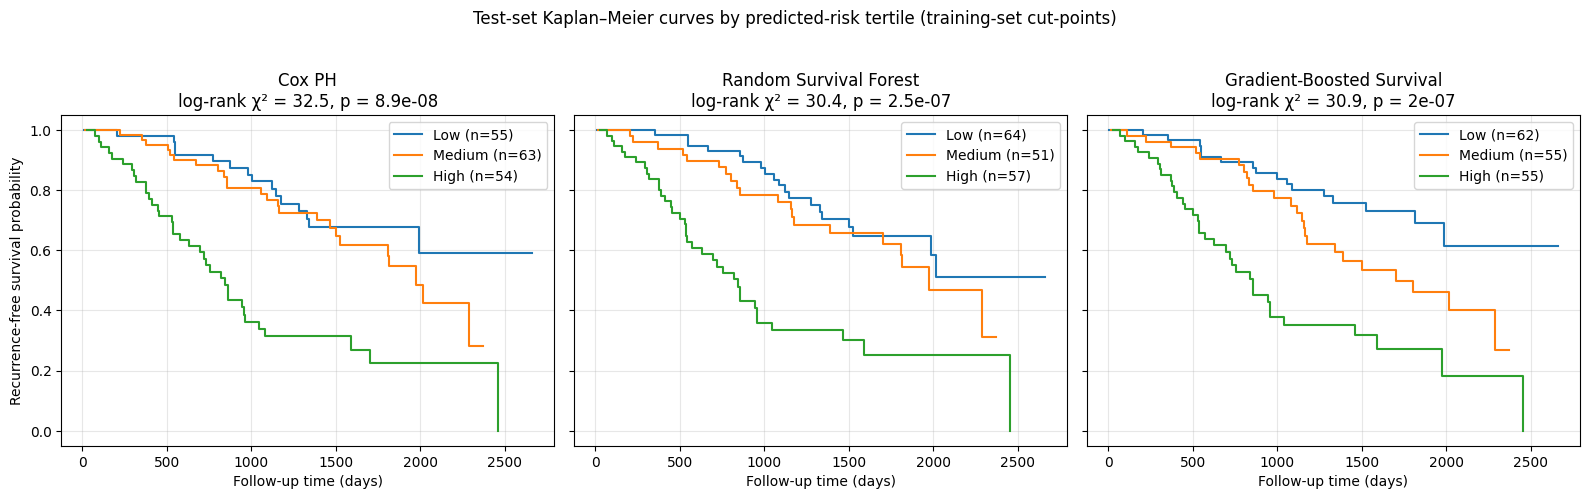

Log-rank test across the three risk groups (test set):


,model,chi_square,degrees_of_freedom,p_value
0,Cox PH,32.46,2,8.94e-08
1,Random Survival Forest,30.40,2,2.50e-07
2,Gradient-Boosted Survival,30.87,2,1.98e-07


Patients and events per risk group:


patients             events            
risk_group                     Low Medium High    Low Medium High
model                                                            
Cox PH                          55     63   54     15     24   36
Gradient-Boosted Survival       62     55   55     16     24   35
Random Survival Forest          64     51   57     19     20   36

In [14]:
from sksurv.compare import compare_survival

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
strat_rows, logrank_rows = [], []
labels = np.array(["Low", "Medium", "High"])

for ax, (name, model) in zip(axes, final_models.items()):
    cuts = np.percentile(model.predict(X_tr), [100 / 3, 200 / 3])
    groups = labels[np.digitize(test_risks[name], cuts)]

    for g in labels:
        mask = groups == g
        t, s = kaplan_meier_estimator(y_test[mask]["cens"], y_test[mask]["time"])
        ax.step(t, s, where="post", label=f"{g} (n={mask.sum()})")
        strat_rows.append({"model": name, "risk_group": g, "patients": int(mask.sum()),
                           "events": int(y_test[mask]["cens"].sum())})

    chisq, pval = compare_survival(y_test, groups)
    logrank_rows.append({"model": name, "chi_square": chisq, "degrees_of_freedom": 2, "p_value": pval})
    ax.set_title(f"{name}\nlog-rank χ² = {chisq:.1f}, p = {pval:.2g}")
    ax.set_xlabel("Follow-up time (days)")
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Recurrence-free survival probability")
plt.suptitle("Test-set Kaplan–Meier curves by predicted-risk tertile (training-set cut-points)", y=1.03)
plt.tight_layout()
plt.show()

print("Log-rank test across the three risk groups (test set):")
logrank_table = pd.DataFrame(logrank_rows)
logrank_table["chi_square"] = logrank_table["chi_square"].round(2)
logrank_table["p_value"] = logrank_table["p_value"].map(lambda p: f"{p:.2e}")
display(logrank_table)

print("Patients and events per risk group:")
display(pd.DataFrame(strat_rows).pivot(index="model", columns="risk_group",
        values=["patients", "events"])[[("patients", g) for g in labels] + [("events", g) for g in labels]])

# 8. Grouped permutation importance

Feature importance is estimated by measuring how much each model's test-set Harrell's C changes when a predictor is shuffled. A larger drop indicates greater reliance on that predictor for the model's risk ranking.

Some original categorical variables are represented by multiple columns after one-hot encoding. All encoded columns belonging to the same original variable are shuffled together, using the same row permutation. This produces one importance estimate for each of the eight original predictors.

Permutation importance measures model reliance. It does not establish that a predictor causes an outcome or that it is clinically important.


model,Cox PH,Gradient-Boosted Survival,Random Survival Forest
variable,,,
pnodes,0.0778,0.0873,0.0804
progrec,0.0606,0.0536,0.0387
horTh,0.0086,0.0098,0.0055
age,0.0001,0.0034,0.0155
tgrade,0.0082,0.0000,0.0014
estrec,-0.0028,0.0000,0.0079
menostat,0.0041,0.0000,0.0006
tsize,0.0019,-0.0017,0.0037


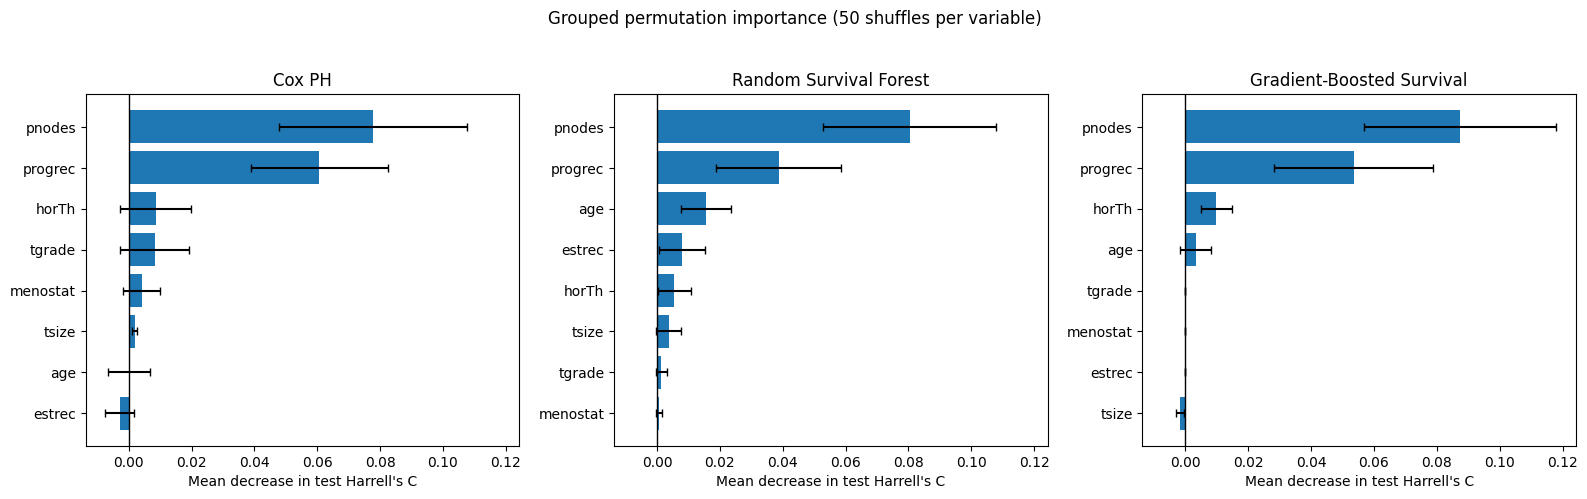

In [15]:
GROUP_NAMES = list(feature_groups)

def grouped_permutation_importance(model, X_eval, y_eval, n_repeats, seed):
    rng = np.random.default_rng(seed)
    X_arr = X_eval.to_numpy()
    col_idx = {g: [X_eval.columns.get_loc(c) for c in cols] for g, cols in feature_groups.items()}
    baseline = harrell(y_eval, model.predict(X_eval))
    importances = {}
    for g in GROUP_NAMES:
        drops = []
        for _ in range(n_repeats):
            perm = rng.permutation(len(X_arr))
            X_perm = X_arr.copy()
            X_perm[:, col_idx[g]] = X_arr[perm][:, col_idx[g]]
            risk = model.predict(pd.DataFrame(X_perm, columns=X_eval.columns, index=X_eval.index))
            drops.append(baseline - harrell(y_eval, risk))
        importances[g] = (np.mean(drops), np.std(drops, ddof=1))
    return importances

ref_importance = []
for name, model in final_models.items():
    imp = grouped_permutation_importance(model, X_te, y_test, n_repeats=50, seed=GLOBAL_SEED)
    for g, (mean, sd) in imp.items():
        ref_importance.append({"model": name, "variable": g, "mean_importance": mean, "sd": sd})
ref_importance = pd.DataFrame(ref_importance)

display(ref_importance.pivot(index="variable", columns="model", values="mean_importance")
        .loc[lambda d: d.mean(axis=1).sort_values(ascending=False).index].round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True)
for ax, name in zip(axes, MODEL_NAMES):
    d = ref_importance[ref_importance["model"] == name].sort_values("mean_importance")
    ax.barh(d["variable"], d["mean_importance"], xerr=d["sd"], capsize=3)
    ax.axvline(0, linewidth=1, color="black")
    ax.set_title(name)
    ax.set_xlabel("Mean decrease in test Harrell's C")
plt.suptitle("Grouped permutation importance (50 shuffles per variable)", y=1.03)
plt.tight_layout()
plt.show()

# 9. Permutation-noise reference analysis

Permutation importance depends partly on which rows are shuffled. Before interpreting differences between models trained on different patient samples, it is useful to estimate how much the importance rankings can vary when the fitted model stays the same.

For this reference analysis, each model fitted on all 514 training patients is kept fixed, and grouped permutation importance is recomputed 30 times using different shuffle seeds. The resulting rankings provide a **full-training-data permutation-noise baseline**. Variation in this comparison comes from the permutation-importance estimation rather than from fitting a different model.

This is an empirical reference, not a strict upper limit. Independently fitted models can sometimes agree more than this baseline by chance. Also, because these reference models use all 514 training patients, this baseline is not directly matched to the smaller sample sizes in Section 10. A size-matched baseline is calculated within that experiment.

For the tree-based models, the full-data fits are also repeated with 30 different random seeds. This adds algorithmic randomness, such as bootstrap sampling and feature or row subsampling, to the permutation noise. The Gradient-Boosted Survival comparison is particularly relevant because its selected subsample fraction is below 1.0.

Ranking agreement is assessed using:

- **Spearman correlation:** Agreement across the ranking of all eight variables.
- **Weighted Kendall's tau:** Ranking agreement that places more weight on agreement near the top.
- **Tie-aware top-three Jaccard index:** The top set includes the three highest variables with positive importance, retaining all ties at the third position. The Jaccard index is the number of shared variables divided by the number of variables in either set. A top set can therefore contain more or fewer than three variables.
- **Forced top-three overlap:** The earlier exactly-three definition is retained for comparison. It selects exactly three variables, breaking ties by column order, and reports the shared count divided by three.


In [16]:
POS_TOL = 1e-9   # importance at or below this is treated as zero
TIE_TOL = 1e-12

def top_set(imp_vec, k=3):
    # Tie-aware top set: the k highest positive-importance variables, keeping ties at the cutoff together
    pos = np.where(imp_vec > POS_TOL)[0]
    if len(pos) == 0:
        return set()
    ordered = pos[np.argsort(-imp_vec[pos])]
    cutoff = imp_vec[ordered[min(k, len(ordered)) - 1]]
    return set(pos[imp_vec[pos] >= cutoff - TIE_TOL])

def top_k_forced(imp_vec, k=3):
    # Version 1 style: exactly k variables, ties broken by column order
    return set(np.argsort(-imp_vec, kind="stable")[:k])

def agreement(a, b):
    rho = spearmanr(a, b).statistic
    wt = weightedtau(a, b).statistic
    ta, tb = top_set(a), top_set(b)
    union = ta | tb
    fa, fb = top_k_forced(a), top_k_forced(b)
    return {"spearman": rho, "weighted_tau": wt,
            "top3_jaccard": len(ta & tb) / len(union) if union else np.nan,
            "top3_forced_overlap": len(fa & fb) / 3}

def importance_vector(model, seed):
    imp = grouped_permutation_importance(model, X_te, y_test, IMPORTANCE_REPEATS, seed)
    return np.array([imp[g][0] for g in GROUP_NAMES])

def pairwise_agreement(vectors):
    rows = [agreement(a, b) for a, b in combinations(vectors, 2)]
    return pd.DataFrame(rows).mean()

def run_noise_analysis():
    noise_rows = []
    for name in MODEL_NAMES:
        vecs = [importance_vector(final_models[name], derived_seed(1, r)) for r in range(NOISE_REPLICATES)]
        noise_rows.append({"model": name, "source": "Full data: permutation noise only", **pairwise_agreement(vecs)})
        if name != "Cox PH":
            refit_vecs = []
            for r in range(NOISE_REPLICATES):
                m = make_models(derived_seed(2, r))[name].fit(X_tr, y_train)
                refit_vecs.append(importance_vector(m, derived_seed(3, r)))
            noise_rows.append({"model": name, "source": "Full data: permutation + algorithmic randomness",
                               **pairwise_agreement(refit_vecs)})
    return pd.DataFrame(noise_rows)

t0 = time.time()
noise_settings = {"replicates": NOISE_REPLICATES, "importance_repeats": IMPORTANCE_REPEATS,
                  "rsf": rsf_params, "gbs": gbs_params, "log": bool(USE_LOG),
                  "global_seed": GLOBAL_SEED, "version": "2.3"}
noise_baseline = cached("noise_baseline", noise_settings, run_noise_analysis)
print(f"Time: {time.time() - t0:.0f} s")
display(noise_baseline.round(3))

Saved results: results/noise_baseline.pkl
Time: 562 s


,model,source,spearman,weighted_tau,top3_jaccard,top3_forced_overlap
0,Cox PH,Full data: permutation noise only,0.902,0.874,0.729,0.819
1,Random Survival Forest,Full data: permutation noise only,0.967,0.958,1.000,1.000
2,Random Survival Forest,Full data: permutation + algorithmic randomness,0.929,0.928,0.967,0.978
3,Gradient-Boosted Survival,Full data: permutation noise only,1.000,1.000,1.000,1.000
4,Gradient-Boosted Survival,Full data: permutation + algorithmic randomness,0.944,0.953,0.967,0.978


# 10. Sample size and ranking stability: disjoint vs. overlapping training sets

The main experiment examines whether feature-importance rankings become more consistent as the number of training patients increases. The sampling design matters because two samples that contain many of the same patients may produce similar rankings partly because the fitted models have seen the same observations.

## Disjoint and overlapping sample designs

In the earlier version, each subsample was drawn from the same 514-patient training pool without preventing two samples from sharing patients. As sample size increased, the samples also tended to share more patients. This mixed the effect of training sample size with the effect of sample overlap.

The current experiment compares three designs for each sample size and each of 25 repetitions:

- **Disjoint pair:** Two samples of size *n* are drawn with no patients in common. Each sample is stratified by event status. The same model is fitted to each sample, and their feature-importance rankings are compared.
- **Overlapping pair:** Two samples of size *n* are drawn independently from the training pool, allowing patients to appear in both. This provides a comparison with the overlapping design used in the earlier version.
- **Size-matched permutation baseline:** For model A in each disjoint pair, feature importance is estimated a second time using new permutation shuffles, without fitting another model. This estimates permutation-noise agreement for a model trained on that sample size. It uses 25 fitted models per size.

The sample sizes are 100, 150, 200, and 256. A disjoint pair cannot be larger than half of the 514-patient training pool. All models are evaluated on the same held-out test set, and fresh random seeds are used for model fits and permutation estimates.

The 25 repetitions are repeated draws from the same training pool; they are not 25 independent cohorts. No patient is shared within a disjoint pair, but a patient can appear in different repetitions. The experiment therefore compares the sampling designs within this dataset, but does not measure the full variation expected across genuinely new patient populations.

This is the most computationally intensive part of the notebook. Results are saved in `RESULTS_DIR` so they can be reloaded on later runs with the same settings.


In [17]:
event_pool = np.where(y_train["cens"])[0]
censor_pool = np.where(~y_train["cens"])[0]
event_rate = y_train["cens"].mean()

SIZES = [100, 150, 200, 256]

def stratified_draw(rng, n, exclude=None):
    n_ev = int(round(n * event_rate))
    ev = event_pool if exclude is None else np.setdiff1d(event_pool, exclude)
    ce = censor_pool if exclude is None else np.setdiff1d(censor_pool, exclude)
    return np.concatenate([rng.choice(ev, n_ev, replace=False),
                           rng.choice(ce, n - n_ev, replace=False)])

assert 2 * int(round(max(SIZES) * event_rate)) <= len(event_pool)
assert 2 * (max(SIZES) - int(round(max(SIZES) * event_rate))) <= len(censor_pool)

SAME_MODEL = "Same model, re-permuted"

def run_stability_experiment():
    perf_records, pair_records = [], []
    t0 = time.time()

    for n in SIZES:
        for rep in range(N_PAIRS):
            rng = np.random.default_rng(np.random.SeedSequence([GLOBAL_SEED, 5, n, rep]))
            A = stratified_draw(rng, n)
            designs = {
                "Disjoint": (A, stratified_draw(rng, n, exclude=A)),
                "Overlapping": (A, stratified_draw(rng, n)),
            }
            for design, (idx_a, idx_b) in designs.items():
                overlap = len(np.intersect1d(idx_a, idx_b)) / n
                for name in MODEL_NAMES:
                    vecs = []
                    for side, idx in [("A", idx_a), ("B", idx_b)]:
                        seed = int(rng.integers(1_000_000_000))
                        model = make_models(seed)[name].fit(X_tr.iloc[idx], y_train[idx])
                        risk = model.predict(X_te)
                        if design == "Disjoint":
                            perf_records.append({
                                "n": n, "rep": rep, "side": side, "model": name,
                                "harrell_c": harrell(y_test, risk),
                                "uno_c": concordance_index_ipcw(y_train, y_test, risk, tau=TAU)[0],
                            })
                        vecs.append(importance_vector(model, seed + 1))
                        if design == "Disjoint" and side == "A":
                            # Same fitted model, new shuffles: size-matched permutation noise
                            repermuted = importance_vector(model, seed + 2)
                    pair_records.append({"n": n, "rep": rep, "design": design, "model": name,
                                         "overlap": overlap, **agreement(*vecs),
                                         **{f"imp_{s}": v for s, v in zip("AB", vecs)}})
                    if design == "Disjoint":
                        pair_records.append({"n": n, "rep": rep, "design": SAME_MODEL, "model": name,
                                             "overlap": 1.0, **agreement(vecs[0], repermuted),
                                             "imp_A": vecs[0], "imp_B": repermuted})
        print(f"n = {n} done ({time.time() - t0:.0f} s elapsed)")
    return pd.DataFrame(perf_records), pd.DataFrame(pair_records)

stability_settings = {"sizes": SIZES, "pairs": N_PAIRS, "importance_repeats": IMPORTANCE_REPEATS,
                      "rsf": rsf_params, "gbs": gbs_params, "log": bool(USE_LOG),
                  "global_seed": GLOBAL_SEED, "version": "2.3"}
perf, pairs = cached("stability_experiment", stability_settings, run_stability_experiment)
print("Performance records:", len(perf), "| Pair records:", len(pairs))

n = 100 done (842 s elapsed)
n = 150 done (1718 s elapsed)
n = 200 done (2640 s elapsed)
n = 256 done (3630 s elapsed)
Saved results: results/stability_experiment.pkl
Performance records: 600 | Pair records: 900


In [18]:
print("Average share of patients shared within a pair (the same-model baseline shares all of them by construction):")
display(pairs.groupby(["design", "n"])["overlap"].mean().unstack().round(3))

Average share of patients shared within a pair (the same-model baseline shares all of them by construction):


n,100,150,200,256
design,,,,
Disjoint,0.000,0.000,0.000,0.000
Overlapping,0.191,0.287,0.395,0.498
"Same model, re-permuted",1.000,1.000,1.000,1.000


## 10a. Predictive performance by training size

Harrell's C and Uno's C are compared across the four training sample sizes. For each size, the tables and plots summarize performance over the repeated model fits. These results show whether adding patients is associated with improved discrimination and whether the pattern differs across the three model types.


harrell_c         uno_c       
                                   mean    std   mean    std
model                     n                                 
Cox PH                    100     0.675  0.019  0.658  0.018
                          150     0.688  0.014  0.669  0.015
                          200     0.693  0.011  0.675  0.010
                          256     0.696  0.007  0.677  0.007
Gradient-Boosted Survival 100     0.681  0.025  0.664  0.027
                          150     0.686  0.016  0.668  0.019
                          200     0.692  0.012  0.675  0.014
                          256     0.693  0.010  0.673  0.012
Random Survival Forest    100     0.692  0.021  0.672  0.022
                          150     0.698  0.014  0.679  0.016
                          200     0.704  0.010  0.684  0.012
                          256     0.704  0.011  0.685  0.012

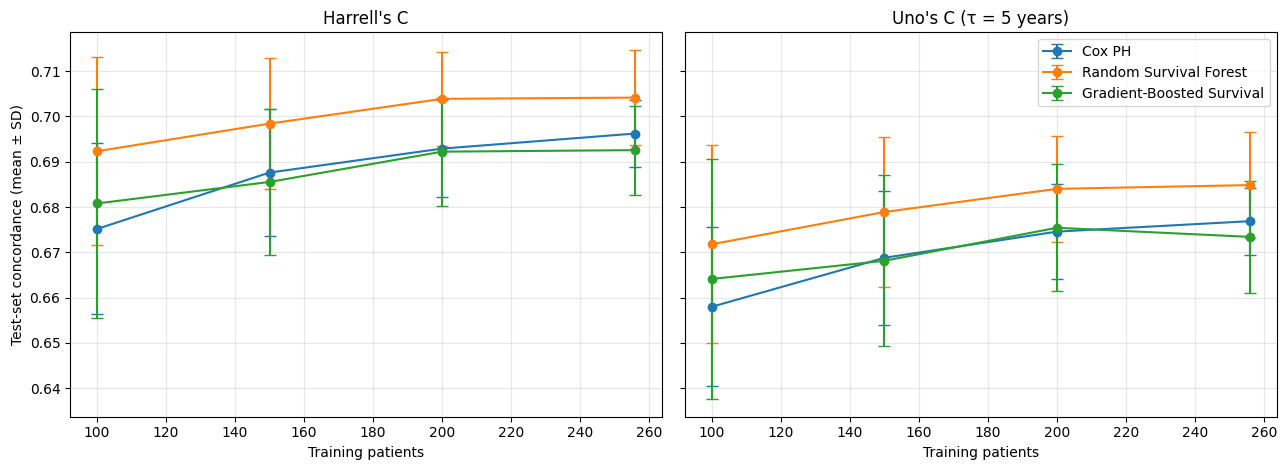

In [19]:
perf_summary = (perf.groupby(["model", "n"])[["harrell_c", "uno_c"]]
                .agg(["mean", "std"]).round(3))
display(perf_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, metric, label in [(axes[0], "harrell_c", "Harrell's C"), (axes[1], "uno_c", "Uno's C (τ = 5 years)")]:
    for name in MODEL_NAMES:
        d = perf[perf["model"] == name].groupby("n")[metric].agg(["mean", "std"])
        ax.errorbar(d.index, d["mean"], yerr=d["std"], marker="o", capsize=4, label=name)
    ax.set_xlabel("Training patients")
    ax.set_title(label)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Test-set concordance (mean ± SD)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 10b. Ranking stability by training size and noise baselines

Agreement between feature-importance rankings from disjoint patient samples is compared with two references: rankings from overlapping samples and repeated permutation estimates from the same fitted model.

The size-matched baseline is important because permutation importance can be noisy, particularly when a fitted model has relatively flat importance values. The gap between disjoint-sample agreement and this baseline is interpreted as a descriptive comparison, not an exact calculation of model instability.

The confidence intervals shown here are based on the 25 repeated pairs. Small differences between neighbouring sample sizes should not be treated as meaningful without considering the broader pattern and uncertainty.


spearman  weighted_tau  top3_jaccard  top3_forced_overlap  valid_jaccard_pairs  \
model                     design                  n                                                                                     
Cox PH                    Disjoint                100     0.402         0.458         0.460                0.600                   25   
                                                  150     0.574         0.569         0.528                0.680                   25   
                                                  200     0.644         0.637         0.588                0.720                   25   
                                                  256     0.686         0.675         0.588                0.720                   25   
                          Overlapping             100     0.623         0.604         0.584                0.707                   25   
                                                  150     0.612         0.607         0.628                0.747                   25   
                                                  200     0.784         0.733         0.728                0.813                   25   
                                                  256     0.748         0.736         0.600                0.733                   25   
                          Same model, re-permuted 100     0.968         0.941         0.880                0.920                   25   
                                                  150     0.945         0.913         0.820                0.880                   25   
                                                  200     0.950         0.928         0.880                0.920                   25   
                                                  256     0.939         0.895         0.800                0.867                   25   
Gradient-Boosted Survival Disjoint                100     0.583         0.599         0.640                0.760                   25   
                                                  150     0.621         0.655         0.588                0.720                   25   
                                                  200     0.658         0.674         0.600                0.733                   25   
                                                  256     0.645         0.692         0.620                0.747                   25   
                          Overlapping             100     0.648         0.653         0.656                0.760                   25   
                                                  150     0.658         0.676         0.568                0.707                   25   
                                                  200     0.742         0.746         0.680                0.787                   25   
                                                  256     0.776         0.755         0.640                0.760                   25   
                          Same model, re-permuted 100     0.924         0.909         0.880                0.920                   25   
                                                  150     0.964         0.947         0.920                0.947                   25   
                                                  200     0.940         0.934         0.960                0.973                   25   
                                                  256     0.959         0.936         0.860                0.907                   25   
Random Survival Forest    Disjoint                100     0.658         0.643         0.660                0.773                   25   
                                                  150     0.661         0.643         0.560                0.707                   25   
                                                  200     0.690         0.722         0.600                0.733                   25   
                                                  256     0.666         0.707     

Pairs excluded from the Jaccard means because both top sets were empty: 0


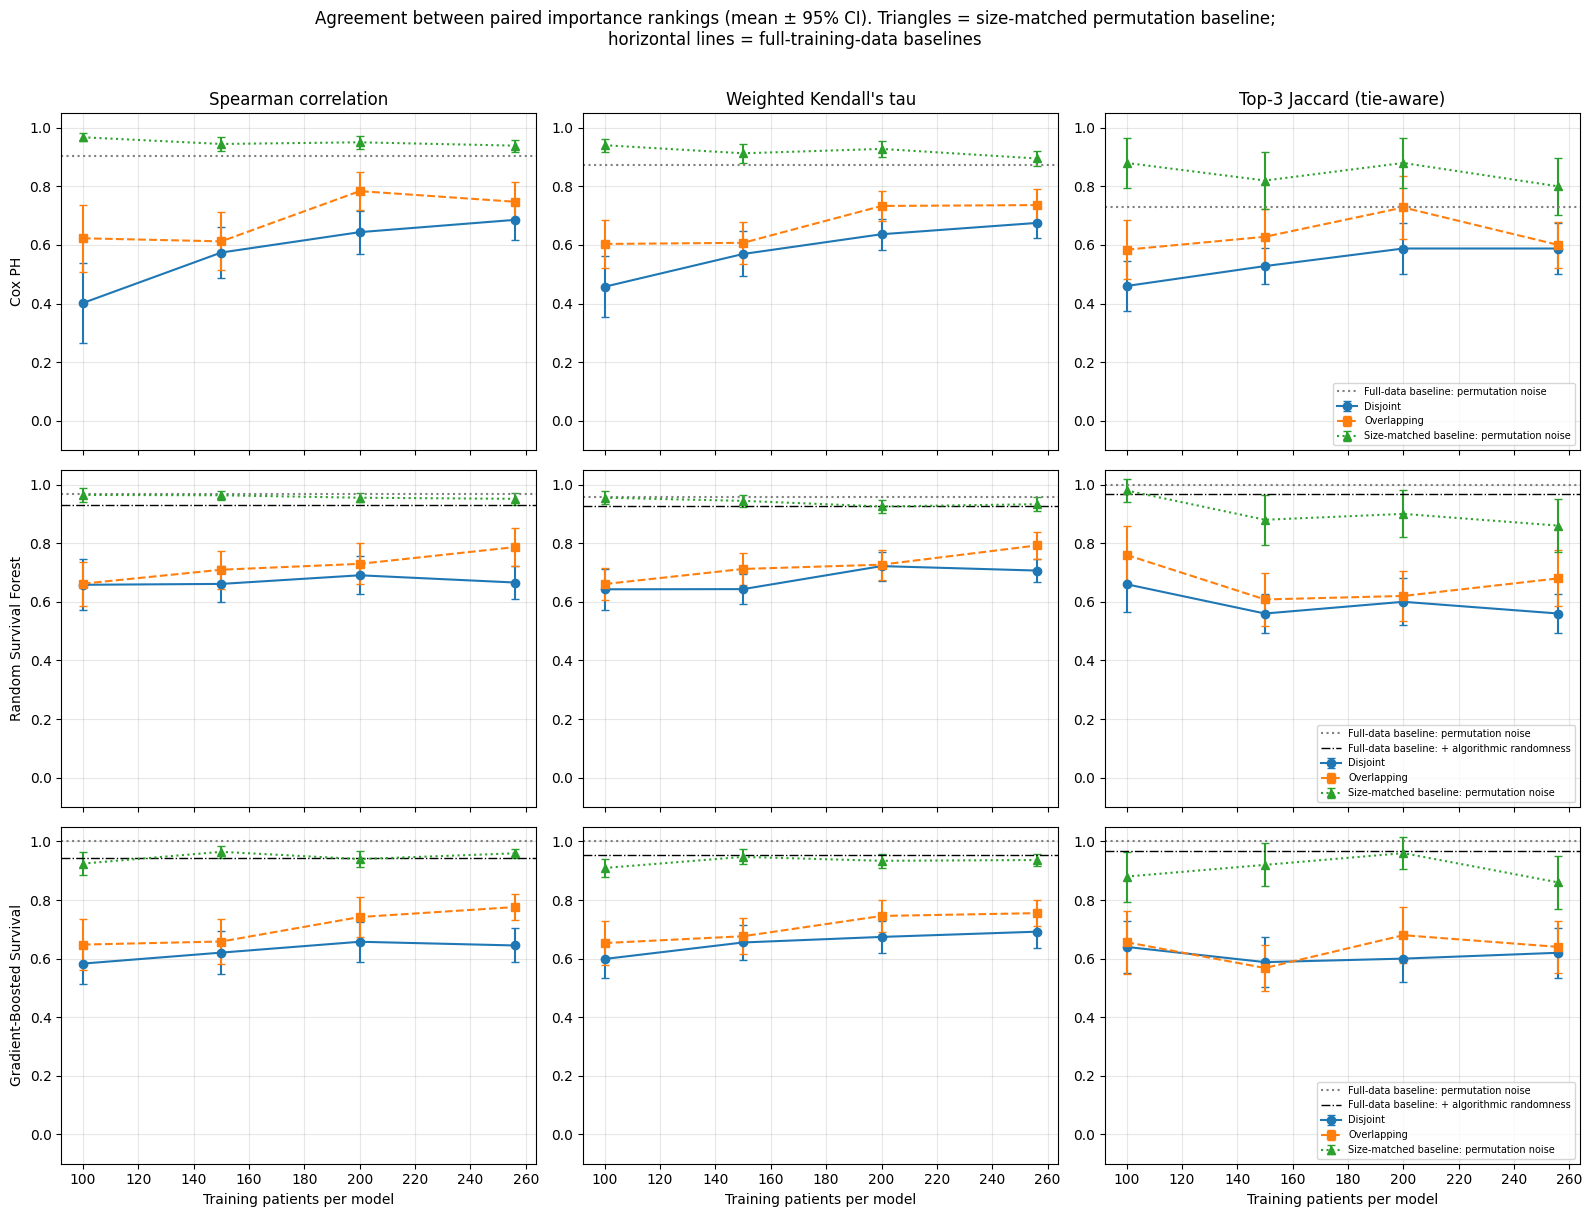

In [20]:
metrics = [("spearman", "Spearman correlation"),
           ("weighted_tau", "Weighted Kendall's tau"),
           ("top3_jaccard", "Top-3 Jaccard (tie-aware)")]
all_metrics = [m for m, _ in metrics] + ["top3_forced_overlap"]

grouped = pairs.groupby(["model", "design", "n"])
stability_summary = grouped[all_metrics].mean().round(3)
stability_summary["valid_jaccard_pairs"] = grouped["top3_jaccard"].count()
stability_summary["total_pairs"] = grouped.size()
display(stability_summary)
excluded = int((stability_summary["total_pairs"] - stability_summary["valid_jaccard_pairs"]).sum())
print(f"Pairs excluded from the Jaccard means because both top sets were empty: {excluded}")

fig, axes = plt.subplots(3, 3, figsize=(16, 12), sharex=True)
for i, name in enumerate(MODEL_NAMES):
    base = noise_baseline[noise_baseline["model"] == name].set_index("source")
    for j, (metric, label) in enumerate(metrics):
        ax = axes[i, j]
        for design, style in [("Disjoint", "-o"), ("Overlapping", "--s"), (SAME_MODEL, ":^")]:
            d = pairs[(pairs["model"] == name) & (pairs["design"] == design)].groupby("n")[metric]
            mean, se = d.mean(), d.std(ddof=1) / np.sqrt(d.count())
            label_d = "Size-matched baseline: permutation noise" if design == SAME_MODEL else design
            ax.errorbar(mean.index, mean, yerr=1.96 * se, fmt=style, capsize=3, label=label_d)
        ax.axhline(base.loc["Full data: permutation noise only", metric], color="grey", linestyle=":",
                   label="Full-data baseline: permutation noise")
        if "Full data: permutation + algorithmic randomness" in base.index:
            ax.axhline(base.loc["Full data: permutation + algorithmic randomness", metric], color="black",
                       linestyle="-.", linewidth=1, label="Full-data baseline: + algorithmic randomness")
        ax.set_ylim(-0.1, 1.05)
        ax.grid(alpha=0.3)
        if i == 0: ax.set_title(label)
        if j == 0: ax.set_ylabel(name)
        if i == 2: ax.set_xlabel("Training patients per model")
for ax in axes[:, 2]:
    ax.legend(loc="lower right", fontsize=7)
plt.suptitle("Agreement between paired importance rankings (mean ± 95% CI). Triangles = size-matched permutation baseline;\n"
             "horizontal lines = full-training-data baselines", y=1.01)
plt.tight_layout()
plt.show()

In [21]:
# How much does overlap inflate apparent stability?
inflation = (pairs.pivot_table(index=["model", "n"], columns="design",
                               values=all_metrics, aggfunc="mean"))
inflation_table = pd.DataFrame({
    m: inflation[(m, "Overlapping")] - inflation[(m, "Disjoint")] for m in all_metrics
})
print("Overlapping minus disjoint agreement (positive = overlap inflates apparent stability):")
display(inflation_table.round(3))

gap_table = pd.DataFrame({
    m: inflation[(m, "Disjoint")] - inflation[(m, SAME_MODEL)] for m in all_metrics
})
print("Disjoint-pair agreement minus the size-matched same-model permutation baseline.\n"
      "Negative values mean independently fitted models agree less than repeated importance estimates\n"
      "of the same fitted model, which is evidence of variation beyond permutation noise.\n"
      "This is a descriptive comparison, not an exact decomposition of model instability.")
display(gap_table.round(3))

Overlapping minus disjoint agreement (positive = overlap inflates apparent stability):


spearman  weighted_tau  top3_jaccard  top3_forced_overlap
model                     n                                                             
Cox PH                    100     0.221         0.146         0.124                0.107
                          150     0.038         0.038         0.100                0.067
                          200     0.140         0.096         0.140                0.093
                          256     0.062         0.061         0.012                0.013
Gradient-Boosted Survival 100     0.065         0.054         0.016                0.000
                          150     0.038         0.021        -0.020               -0.013
                          200     0.084         0.072         0.080                0.053
                          256     0.131         0.063         0.020                0.013
Random Survival Forest    100     0.004         0.018         0.100                0.067
                          150     0.048         0.069         0.048                0.027
                          200     0.039         0.005         0.020                0.013
                          256     0.121         0.086         0.120                0.080

Disjoint-pair agreement minus the size-matched same-model permutation baseline.
Negative values mean independently fitted models agree less than repeated importance estimates
of the same fitted model, which is evidence of variation beyond permutation noise.
This is a descriptive comparison, not an exact decomposition of model instability.


spearman  weighted_tau  top3_jaccard  top3_forced_overlap
model                     n                                                             
Cox PH                    100    -0.566        -0.483        -0.420               -0.320
                          150    -0.370        -0.344        -0.292               -0.200
                          200    -0.307        -0.291        -0.292               -0.200
                          256    -0.253        -0.220        -0.212               -0.147
Gradient-Boosted Survival 100    -0.341        -0.311        -0.240               -0.160
                          150    -0.344        -0.292        -0.332               -0.227
                          200    -0.282        -0.260        -0.360               -0.240
                          256    -0.314        -0.245        -0.240               -0.160
Random Survival Forest    100    -0.307        -0.313        -0.320               -0.213
                          150    -0.302        -0.301        -0.320               -0.213
                          200    -0.265        -0.204        -0.300               -0.200
                          256    -0.286        -0.226        -0.300               -0.200

## 10c. Which variables rank highly, and how consistently?

Feature importance across the fitted models in the disjoint-sample experiment is summarized in three ways:

1. **Positive-importance frequency:** The proportion of fitted models for which a variable has positive mean permutation importance. This indicates how often shuffling the variable reduces the model's measured ranking performance.
2. **Tie-aware top-three frequency:** The proportion of fitted models in which the variable appears in the top set defined in Section 9.
3. **Forced top-three frequency:** The earlier exactly-three definition is included for comparison with the tie-aware approach.

These summaries describe how the models use the predictors. They are not evidence that a variable causes the outcome or is necessarily the most important factor for clinical decisions.


In [22]:
long_rows = []
for _, r in pairs[pairs["design"] == "Disjoint"].iterrows():
    for side in "AB":
        vec = r[f"imp_{side}"]
        tie_aware, forced = top_set(vec), top_k_forced(vec)
        for i, g in enumerate(GROUP_NAMES):
            long_rows.append({"model": r["model"], "n": r["n"], "rep": r["rep"], "side": side,
                              "variable": g, "importance": vec[i],
                              "positive": vec[i] > POS_TOL,
                              "top3_tie_aware": i in tie_aware, "top3_forced": i in forced,
                              "top_set_size": len(tie_aware)})
imp_long = pd.DataFrame(long_rows)

def frequency(col):
    return imp_long.groupby(["model", "variable", "n"])[col].mean().unstack("n")

positive_freq = frequency("positive")
top3_freq = frequency("top3_tie_aware")
top3_forced_freq = frequency("top3_forced")

for name in MODEL_NAMES:
    order = top3_freq.loc[name].sort_values(SIZES[-1], ascending=False).index
    table = pd.concat({"Positive importance": positive_freq.loc[name].loc[order],
                       "Top 3 (tie-aware)": top3_freq.loc[name].loc[order],
                       "Top 3 (forced, v1)": top3_forced_freq.loc[name].loc[order]}, axis=1)
    print(f"\n{name}: share of fitted models (columns = training patients)")
    display(table.round(2))


Cox PH: share of fitted models (columns = training patients)


Positive importance                   Top 3 (tie-aware)                   Top 3 (forced, v1)                  
n                        100   150   200   256               100   150   200   256                100   150   200   256
variable                                                                                                               
pnodes                  1.00  1.00  1.00  1.00              0.98  1.00  1.00  1.00               0.98  1.00  1.00  1.00
progrec                 0.94  1.00  1.00  1.00              0.86  0.94  0.94  0.98               0.86  0.94  0.94  0.98
tgrade                  0.88  0.90  1.00  1.00              0.44  0.44  0.48  0.46               0.44  0.44  0.48  0.46
horTh                   0.78  0.90  0.98  1.00              0.20  0.26  0.38  0.28               0.20  0.26  0.38  0.28
menostat                0.70  0.74  0.74  0.86              0.20  0.04  0.12  0.18               0.20  0.04  0.12  0.18
age                     0.78  0.72  0.66  0.76              0.12  0.16  0.08  0.08               0.12  0.16  0.08  0.08
tsize                   0.48  0.52  0.60  0.58              0.12  0.16  0.00  0.02               0.12  0.16  0.00  0.02
estrec                  0.38  0.40  0.42  0.30              0.08  0.00  0.00  0.00               0.08  0.00  0.00  0.00


Random Survival Forest: share of fitted models (columns = training patients)


Positive importance                   Top 3 (tie-aware)                   Top 3 (forced, v1)                  
n                        100   150   200   256               100   150   200   256                100   150   200   256
variable                                                                                                               
progrec                 1.00  1.00  1.00  1.00              1.00  1.00  1.00  1.00               1.00  1.00  1.00  1.00
pnodes                  1.00  1.00  1.00  1.00              1.00  1.00  1.00  1.00               1.00  1.00  1.00  1.00
estrec                  0.86  0.92  0.92  0.98              0.36  0.36  0.34  0.40               0.36  0.36  0.34  0.40
age                     0.54  0.76  0.88  0.98              0.00  0.06  0.12  0.24               0.00  0.06  0.12  0.24
tsize                   0.80  0.82  0.90  0.82              0.48  0.34  0.36  0.24               0.48  0.34  0.36  0.24
horTh                   0.82  0.96  0.96  0.98              0.16  0.24  0.16  0.12               0.16  0.24  0.16  0.12
menostat                0.40  0.38  0.38  0.54              0.00  0.00  0.00  0.00               0.00  0.00  0.00  0.00
tgrade                  0.52  0.76  0.76  0.86              0.00  0.00  0.02  0.00               0.00  0.00  0.02  0.00


Gradient-Boosted Survival: share of fitted models (columns = training patients)


Positive importance                   Top 3 (tie-aware)                   Top 3 (forced, v1)                  
n                        100   150   200   256               100   150   200   256                100   150   200   256
variable                                                                                                               
progrec                 1.00  1.00  1.00  1.00              0.94  0.96  1.00  1.00               0.94  0.96  1.00  1.00
pnodes                  1.00  1.00  1.00  1.00              1.00  1.00  1.00  1.00               1.00  1.00  1.00  1.00
age                     0.90  0.92  0.90  1.00              0.34  0.50  0.24  0.36               0.34  0.50  0.24  0.36
tsize                   0.76  0.68  0.92  0.82              0.42  0.26  0.42  0.34               0.42  0.26  0.42  0.34
horTh                   0.58  0.66  0.80  0.78              0.14  0.16  0.22  0.24               0.14  0.16  0.22  0.24
estrec                  0.62  0.62  0.64  0.58              0.14  0.12  0.10  0.06               0.14  0.12  0.10  0.06
menostat                0.08  0.04  0.04  0.02              0.00  0.00  0.00  0.00               0.00  0.00  0.00  0.00
tgrade                  0.32  0.32  0.22  0.28              0.02  0.00  0.02  0.00               0.02  0.00  0.02  0.00

In [23]:
# How often does the tie-aware top set differ from exactly three variables?
set_sizes = (imp_long.drop_duplicates(["model", "n", "rep", "side"])
             .groupby(["model", "n"])["top_set_size"]
             .agg(fewer_than_3=lambda v: (v < 3).mean(),
                  exactly_3=lambda v: (v == 3).mean(),
                  more_than_3=lambda v: (v > 3).mean()))
print("Share of fitted models whose tie-aware top set has fewer than, exactly, or more than three variables:")
display(set_sizes.round(2))

Share of fitted models whose tie-aware top set has fewer than, exactly, or more than three variables:


fewer_than_3  exactly_3  more_than_3
model                     n                                        
Cox PH                    100           0.0        1.0          0.0
                          150           0.0        1.0          0.0
                          200           0.0        1.0          0.0
                          256           0.0        1.0          0.0
Gradient-Boosted Survival 100           0.0        1.0          0.0
                          150           0.0        1.0          0.0
                          200           0.0        1.0          0.0
                          256           0.0        1.0          0.0
Random Survival Forest    100           0.0        1.0          0.0
                          150           0.0        1.0          0.0
                          200           0.0        1.0          0.0
                          256           0.0        1.0          0.0

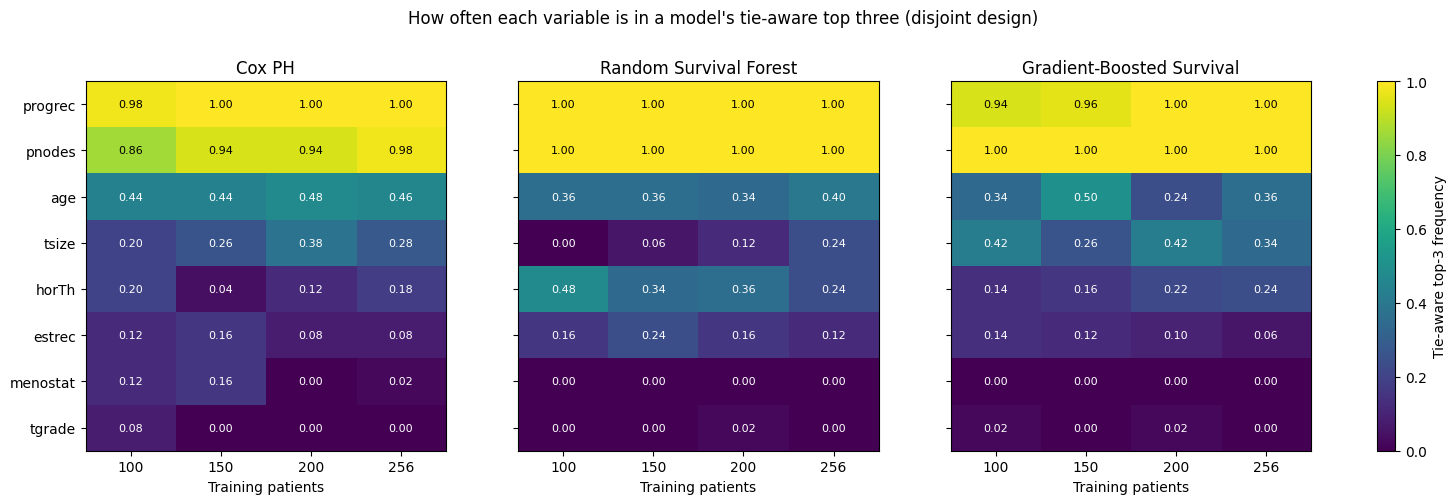

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for ax, name in zip(axes, MODEL_NAMES):
    d = top3_freq.loc[name].sort_values(SIZES[-1], ascending=False)
    im = ax.imshow(d.to_numpy(), aspect="auto", vmin=0, vmax=1, cmap="viridis")
    ax.set_xticks(range(len(SIZES)), SIZES)
    ax.set_yticks(range(len(d)), d.index)
    ax.set_xlabel("Training patients")
    ax.set_title(name)
    for (i, j), v in np.ndenumerate(d.to_numpy()):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color="white" if v < 0.6 else "black", fontsize=8)
fig.colorbar(im, ax=axes, fraction=0.02, label="Tie-aware top-3 frequency")
plt.suptitle("How often each variable is in a model's tie-aware top three (disjoint design)", y=1.03)
plt.show()

# 11. Combined performance and stability results

This section brings the predictive-performance and ranking-stability summaries together. A model can discriminate between patients reasonably well while producing feature-importance rankings that change across training samples.

The combined table compares average Harrell's C and Uno's C with the ranking-agreement measures for the disjoint-sample design. Predictive performance and explanation stability are treated as related, but distinct, properties.


,model,n,harrell_c,uno_c,spearman,weighted_tau,top3_jaccard
0,Cox PH,100,0.675,0.658,0.402,0.458,0.460
1,Cox PH,150,0.688,0.669,0.574,0.569,0.528
2,Cox PH,200,0.693,0.675,0.644,0.637,0.588
3,Cox PH,256,0.696,0.677,0.686,0.675,0.588
4,Gradient-Boosted Survival,100,0.681,0.664,0.583,0.599,0.640
5,Gradient-Boosted Survival,150,0.686,0.668,0.621,0.655,0.588
6,Gradient-Boosted Survival,200,0.692,0.675,0.658,0.674,0.600
7,Gradient-Boosted Survival,256,0.693,0.673,0.645,0.692,0.620
8,Random Survival Forest,100,0.692,0.672,0.658,0.643,0.660
9,Random Survival Forest,150,0.698,0.679,0.661,0.643,0.560


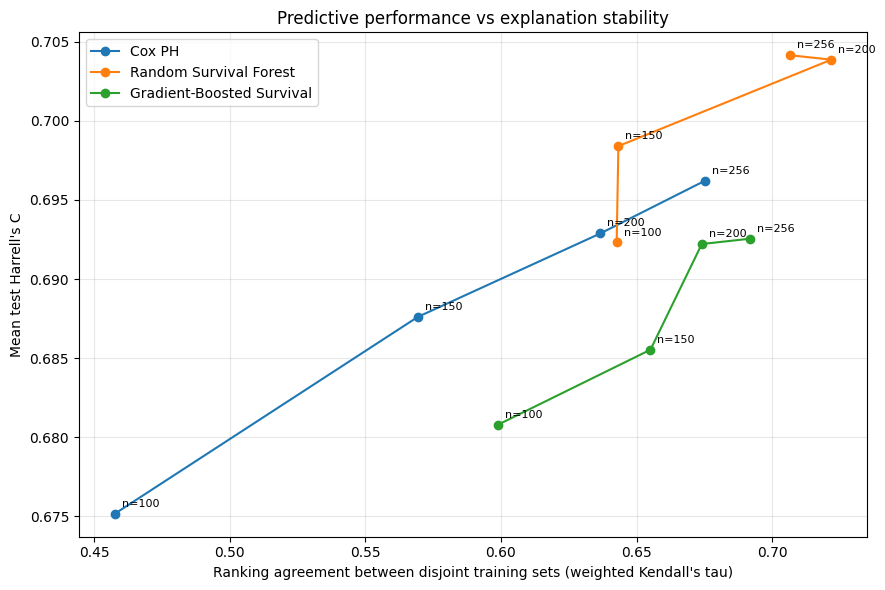

In [25]:
combined = (perf.groupby(["model", "n"])[["harrell_c", "uno_c"]].mean()
            .join(pairs[pairs["design"] == "Disjoint"]
                  .groupby(["model", "n"])[["spearman", "weighted_tau", "top3_jaccard"]].mean())
            .reset_index())
display(combined.round(3))

plt.figure(figsize=(9, 6))
for name in MODEL_NAMES:
    d = combined[combined["model"] == name]
    plt.plot(d["weighted_tau"], d["harrell_c"], marker="o", label=name)
    for _, r in d.iterrows():
        plt.annotate(f"n={r['n']}", (r["weighted_tau"], r["harrell_c"]),
                     xytext=(5, 5), textcoords="offset points", fontsize=8)
plt.xlabel("Ranking agreement between disjoint training sets (weighted Kendall's tau)")
plt.ylabel("Mean test Harrell's C")
plt.title("Predictive performance vs explanation stability")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 12. Discussion, limitations and conclusion

## 12.1 Model selection

For the Cox model, the log-transformed specification performed better in cross-validation than the raw-predictor specification. Its mean cross-validated C-index was 0.6872 (SD 0.0392), compared with 0.6716 (SD 0.0520) for the raw predictors. The log-transformed specification was therefore selected for the remaining analysis.

For Gradient-Boosted Survival, tuning improved the cross-validated C-index from 0.6702 under the earlier configuration to 0.6867 under the selected configuration. The selected settings were 100 estimators, learning rate 0.1, maximum depth 1, and subsample 0.8. This is an improvement in cross-validation performance; it does not by itself establish that boosting is the best-performing model.

## 12.2 Predictive performance

The Random Survival Forest had the highest Harrell's C (0.707), followed by Cox PH (0.698) and Gradient-Boosted Survival (0.689). The same general ordering appears in Uno's C and mean time-dependent AUC. The IBS values were 0.159 for Cox PH, 0.160 for Random Survival Forest, and 0.163 for Gradient-Boosted Survival; all three were lower than the Kaplan–Meier reference value of 0.195.

However, the paired bootstrap confidence intervals for all three pairwise Harrell's C differences included zero. The observed differences are therefore not sufficient to establish a clear performance winner. The three models had broadly comparable discrimination on this test set, with Random Survival Forest producing the highest point estimates.

## 12.3 Risk stratification

All three models separated the test patients into low-, medium-, and high-risk groups with statistically significant log-rank tests. The p-values were 8.94 × 10⁻⁸ for Cox PH, 2.50 × 10⁻⁷ for Random Survival Forest, and 1.98 × 10⁻⁷ for Gradient-Boosted Survival.

The risk groups contained between 51 and 64 patients each. The high-risk groups had 35 or 36 observed events, compared with 15 to 19 events in the low-risk groups. This pattern is consistent with the models identifying groups with different observed survival experiences. The log-rank results show separation in this test set; they do not establish clinical utility or external validity.

## 12.4 Training sample size and predictive performance

Across the sample-size experiment, average Harrell's C generally increased as the training sample grew, although the gains became smaller at the larger sizes. For example, Cox PH increased from 0.675 at 100 patients to 0.696 at 256 patients. Random Survival Forest increased from 0.692 to 0.704, while Gradient-Boosted Survival increased from 0.681 to 0.693.

For the tree-based models, the improvement was modest between 200 and 256 patients. These results suggest that larger samples helped predictive performance in this experiment, but the size of the improvement differed by model.

## 12.5 Feature-importance stability

The disjoint-sample results show different patterns across models. For Cox PH, Spearman agreement increased from 0.402 at 100 patients to 0.686 at 256 patients. For Random Survival Forest, agreement ranged from 0.658 to 0.690, without a consistent increase across every sample size. For Gradient-Boosted Survival, it increased from 0.583 to 0.658 at 200 patients, then was 0.645 at 256 patients.

The increase in ranking agreement with sample size was clearer for Cox PH than for the two tree-based models. For the tree-based models, the results do not show a clear, consistent improvement beyond approximately 150–200 patients. Small differences between neighbouring sample sizes should be interpreted cautiously because the experiment uses 25 repeated pairs and the confidence intervals overlap in many comparisons.

The size-matched same-model baseline was substantially higher than the disjoint-sample agreement. For example, Spearman agreement for Cox PH was between 0.939 and 0.968 across the four sizes, compared with 0.402–0.686 for disjoint samples. The corresponding baseline ranges were 0.924–0.964 for Gradient-Boosted Survival and 0.951–0.965 for Random Survival Forest. This indicates that permutation shuffling alone does not explain all the lower agreement between independently fitted models. The gap is a descriptive comparison, not an exact decomposition of instability.

## 12.6 Effect of overlapping training samples

The overlapping samples generally produced higher agreement than the disjoint samples, although the size of the difference varied by model and sample size. At 200 patients, for example, Spearman agreement was 0.784 versus 0.644 for Cox PH, 0.742 versus 0.658 for Gradient-Boosted Survival, and 0.730 versus 0.690 for Random Survival Forest.

The average share of patients in common in the overlapping pairs increased from 19.1% at 100 patients to 49.8% at 256 patients. This helps explain why overlapping samples can produce higher apparent agreement: the fitted models have seen some of the same patients. The comparison supports the use of disjoint samples when the goal is to examine how rankings change across different patient samples.

## 12.7 Predictor importance across models

`pnodes` and `progrec` were consistently important across the models. In the disjoint-sample experiment, both had positive importance in all fitted models at every sample size for all three model types. They also appeared in the tie-aware top-three set in every Random Survival Forest and Gradient-Boosted Survival fit, and in nearly all Cox fits.

The other predictors varied more by model. For example, `tgrade` appeared frequently in the Cox model's top-three set, while `age` and `tsize` appeared more often in the top-three summaries for the tree-based models. This reinforces that feature importance is model-dependent and that a single fitted model's ranking may not tell the whole story.

## 12.8 Limitations and future work

Several limitations should be considered when interpreting these findings:

- **One dataset and one test set:** The analysis uses the GBSG2 dataset and a fixed 172-patient test set. The results need external validation on another patient cohort before they can be generalized.
- **Repeated draws from one training pool:** The 25 pairs at each sample size reuse patients across repetitions. They are not independent samples from the wider population, and their variability should not be interpreted as between-cohort variability.
- **Restricted sample-size range:** Disjoint pairs can only be created up to 256 patients because both samples must fit within the 514-patient training pool. The experiment does not measure disjoint-sample stability at the full training size.
- **Hyperparameters held fixed:** The models are tuned using all 514 training patients and those settings are reused for the smaller samples. Different hyperparameters might be better for smaller training sets.
- **Correlated predictors:** Grouping the encoded columns of each categorical variable avoids splitting one original variable across separate importance values. However, correlated predictors, such as the receptor measurements, can still share or mask one another's permutation importance.
- **Permutation importance is not causation:** The importance scores show how much the fitted models rely on predictors for their risk rankings. They do not establish causal effects or clinical usefulness.
- **Performance uncertainty:** Bootstrap confidence intervals and paired comparisons are calculated for Harrell's C only. The other test metrics are reported as point estimates.

Future work could repeat the analysis with an independent survival dataset or an external breast cancer cohort. Further investigation could also examine how correlated predictors and alternative explainability methods affect ranking stability.

## 12.9 Conclusion

The results show why survival models should not be evaluated using predictive performance alone. The three models achieved broadly similar test-set discrimination, but their feature-importance rankings behaved differently when the training patients changed. The Cox model showed a more consistent increase in ranking agreement as sample size grew, while the tree-based models showed less consistent changes. The comparison between overlapping and disjoint samples also showed that shared patients can increase apparent agreement.

Predictive performance and explanation stability answer different questions. Both are relevant when assessing whether a survival model's predictions and explanations are dependable enough to investigate further.
